# Retail Sales Exploratory Data Analysis (EDA)

## Introduction
Exploratory Data Analysis (EDA) helps identify patterns, trends and relationships in sales data. This project analyses retail transactions to understand sales performance, product preferences and customer purchasing behaviour.

The analysis uses Python to examine sales trends over time, customer demographics, product performance and revenue distribution across categories.

## Objectives
- Examine the dataset structure and descriptive statistics.
- Analyse monthly and quarterly sales trends.
- Study customer purchasing patterns by age group and gender.
- Identify the top 10 products based on sales.
- Analyse revenue generated by each product category.
- Explore relationships between numerical variables using a correlation heatmap.
- Present additional visualisations and actionable business recommendations.

## Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the retail sales dataset
url = "https://gist.githubusercontent.com/summerofgeorge/33dbb09adbdea670c31ee2c4fc9f2617/raw/32d15ca6e8989f74b6a3fa1fef317f394efd48f4/sales_data.csv"

df = pd.read_csv(url)

# Display the first five records
print("First five records:")
display(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
display(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())


First five records:


,order_id,customer_id,product_id,product_name,category,unit_price,quantity,order_date,customer_age,customer_gender,country
0,1,150,9,Tablet,Electronics,611,1,11/14/2022,62,Female,Germany
1,2,176,36,Smartphone,Electronics,751,4,10/6/2022,23,Male,Canada
2,3,37,22,Jacket,Accessories,821,4,5/7/2022,54,Male,UK
3,4,143,42,Shoes,Electronics,395,4,5/9/2022,50,Male,Germany
4,5,163,26,Jacket,Accessories,301,1,2/27/2022,39,Male,Australia


Dataset shape: (500, 11)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   order_id         500 non-null    int64 
 1   customer_id      500 non-null    int64 
 2   product_id       500 non-null    int64 
 3   product_name     500 non-null    object
 4   category         500 non-null    object
 5   unit_price       500 non-null    int64 
 6   quantity         500 non-null    int64 
 7   order_date       500 non-null    object
 8   customer_age     500 non-null    int64 
 9   customer_gender  500 non-null    object
 10  country          500 non-null    object
dtypes: int64(6), object(5)
memory usage: 43.1+ KB

Missing values:


,0
order_id,0
customer_id,0
product_id,0
product_name,0
category,0
unit_price,0
quantity,0
order_date,0
customer_age,0
customer_gender,0



Duplicate records: 0


In [2]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all"))

Column names:
['order_id', 'customer_id', 'product_id', 'product_name', 'category', 'unit_price', 'quantity', 'order_date', 'customer_age', 'customer_gender', 'country']

Data types:


,0
order_id,int64
customer_id,int64
product_id,int64
product_name,object
category,object
unit_price,int64
quantity,int64
order_date,object
customer_age,int64
customer_gender,object



Missing values:


,0
order_id,0
customer_id,0
product_id,0
product_name,0
category,0
unit_price,0
quantity,0
order_date,0
customer_age,0
customer_gender,0



Descriptive statistics:


,order_id,customer_id,product_id,product_name,category,unit_price,quantity,order_date,customer_age,customer_gender,country
count,500.000000,500.000000,500.000000,500,500,500.000000,500.000000,500,500.000000,500,500
unique,NaN,NaN,NaN,10,3,NaN,NaN,261,NaN,2,6
top,NaN,NaN,NaN,T-shirt,Accessories,NaN,NaN,5/2/2022,NaN,Male,Canada
freq,NaN,NaN,NaN,61,199,NaN,NaN,5,NaN,262,93
mean,250.500000,101.312000,25.360000,NaN,NaN,568.204000,2.574000,NaN,41.380000,NaN,NaN
std,144.481833,58.975001,14.087986,NaN,NaN,275.301784,1.145053,NaN,13.749826,NaN,NaN
min,1.000000,2.000000,1.000000,NaN,NaN,51.000000,1.000000,NaN,18.000000,NaN,NaN
25%,125.750000,47.750000,14.000000,NaN,NaN,345.000000,2.000000,NaN,28.000000,NaN,NaN
50%,250.500000,106.000000,25.000000,NaN,NaN,558.000000,3.000000,NaN,42.000000,NaN,NaN
75%,375.250000,150.000000,37.000000,NaN,NaN,821.000000,4.000000,NaN,53.000000,NaN,NaN


## 2. Data Preparation

Before performing exploratory data analysis, the dataset is prepared by converting the order date into datetime format and creating additional columns required for sales analysis.

Total sales is calculated by multiplying the unit price by the quantity purchased. Customer age groups and time-based columns are also created to support further analysis.

In [3]:

# Check and remove duplicate records
print("Duplicate records before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

# Convert order_date into datetime format
df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce"
)

# Create total sales column
df["total_sales"] = df["unit_price"] * df["quantity"]

# Extract month and quarter
df["month"] = df["order_date"].dt.to_period("M")
df["quarter"] = df["order_date"].dt.to_period("Q")

# Create customer age groups
df["age_group"] = pd.cut(
    df["customer_age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"]
)

# Display prepared dataset
print("\nPrepared dataset:")
display(df.head())

print("\nFinal dataset shape:", df.shape)
print("Invalid dates:", df["order_date"].isna().sum())
print("Total sales revenue:", df["total_sales"].sum())


Duplicate records before cleaning: 0

Prepared dataset:


,order_id,customer_id,product_id,product_name,category,unit_price,quantity,order_date,customer_age,customer_gender,country,total_sales,month,quarter,age_group
0,1,150,9,Tablet,Electronics,611,1,2022-11-14,62,Female,Germany,611,2022-11,2022Q4,56-65
1,2,176,36,Smartphone,Electronics,751,4,2022-10-06,23,Male,Canada,3004,2022-10,2022Q4,18-25
2,3,37,22,Jacket,Accessories,821,4,2022-05-07,54,Male,UK,3284,2022-05,2022Q2,46-55
3,4,143,42,Shoes,Electronics,395,4,2022-05-09,50,Male,Germany,1580,2022-05,2022Q2,46-55
4,5,163,26,Jacket,Accessories,301,1,2022-02-27,39,Male,Australia,301,2022-02,2022Q1,36-45



Final dataset shape: (500, 15)
Invalid dates: 0
Total sales revenue: 731790


## 3. Descriptive Statistical Analysis

Descriptive statistics provide an overview of the numerical variables in the retail dataset. Mean, median, mode and standard deviation are calculated to understand sales amounts, product prices, quantities purchased and customer ages.

In [4]:

# Select important numerical columns
columns_to_analyse = [
    "unit_price",
    "quantity",
    "customer_age",
    "total_sales"
]

# Calculate mean, median, mode and standard deviation
statistics = pd.DataFrame({
    "Mean": df[columns_to_analyse].mean(),
    "Median": df[columns_to_analyse].median(),
    "Mode": df[columns_to_analyse].mode().iloc[0],
    "Standard Deviation": df[columns_to_analyse].std()
})

print("Descriptive Statistics:")
display(statistics.round(2))


Descriptive Statistics:


,Mean,Median,Mode,Standard Deviation
unit_price,568.20,558.0,841.0,275.30
quantity,2.57,3.0,4.0,1.15
customer_age,41.38,42.0,57.0,13.75
total_sales,1463.58,1262.0,1548.0,1004.79


### Observations

1. The average unit price is 568.20, while the median is 558, indicating that product prices are relatively centred around these values.
2. The average quantity purchased per transaction is approximately 2.57 units, with a median of 3 units.
3. The average customer age is 41.38 years, suggesting that the dataset includes customers across different age groups.
4. The average sales value per transaction is 1,463.58, while the median is 1,262. The higher mean suggests that some transactions have comparatively larger sales values.
5. The standard deviation of total sales is 1,004.79, indicating considerable variation in transaction values.

## 4. Sales Trend Analysis

Sales trends are analysed over monthly and quarterly periods to understand changes in revenue over time. These comparisons help identify stronger and weaker sales periods.

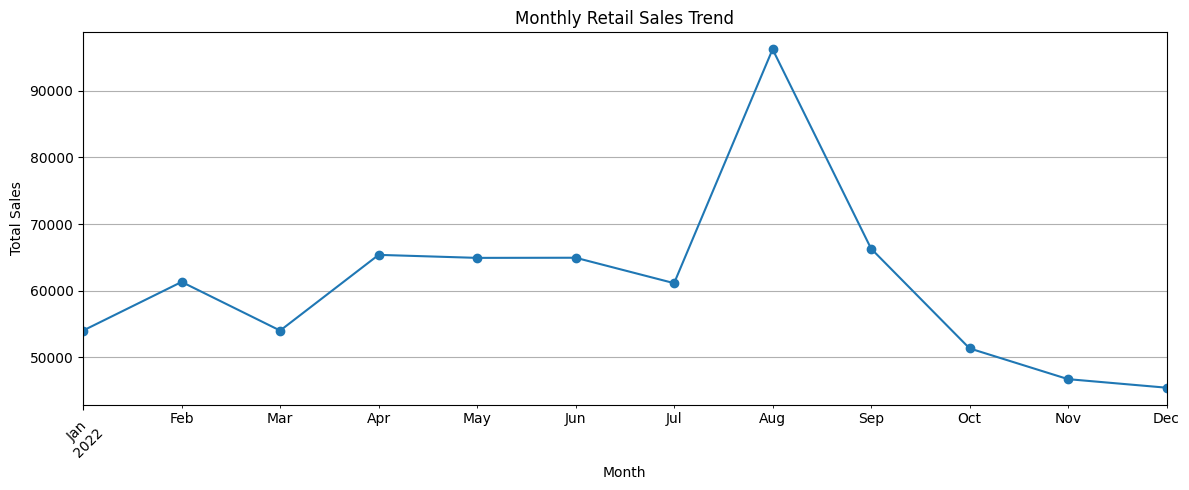

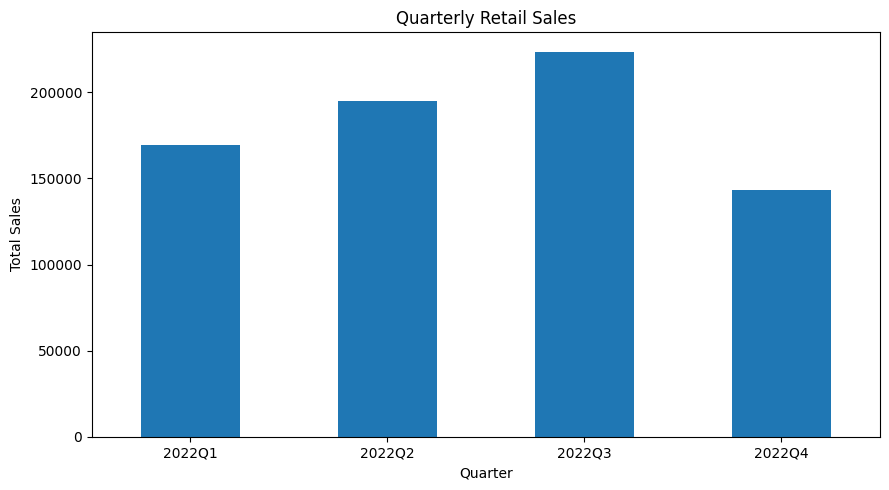

Monthly Sales:


,total_sales
month,
2022-01,54020
2022-02,61316
2022-03,54013
2022-04,65379
2022-05,64927
2022-06,64948
2022-07,61130
2022-08,96241
2022-09,66313


Quarterly Sales:


,total_sales
quarter,
2022Q1,169349
2022Q2,195254
2022Q3,223684
2022Q4,143503


In [5]:

# Calculate monthly sales
monthly_sales = df.groupby("month")["total_sales"].sum()

# Calculate quarterly sales
quarterly_sales = df.groupby("quarter")["total_sales"].sum()

# Monthly sales trend
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Quarterly sales trend
plt.figure(figsize=(9, 5))
quarterly_sales.plot(kind="bar")
plt.title("Quarterly Retail Sales")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Display sales values
print("Monthly Sales:")
display(monthly_sales)

print("Quarterly Sales:")
display(quarterly_sales)


### Observations

1. August recorded the highest monthly sales of 96,241, making it the strongest sales month.
2. December recorded the lowest monthly sales of 45,441.
3. Sales increased significantly from July to August, followed by a decline in September.
4. The third quarter (Q3) generated the highest revenue of 223,684.
5. The fourth quarter (Q4) recorded the lowest quarterly revenue of 143,503.
6. Overall, sales performance was strongest during Q3, while Q4 showed a noticeable decline.

## 5. Customer Demographic Analysis

Customer demographic analysis helps understand how different customer groups contribute to retail sales. This section examines sales distribution by gender and age group to identify important customer segments.

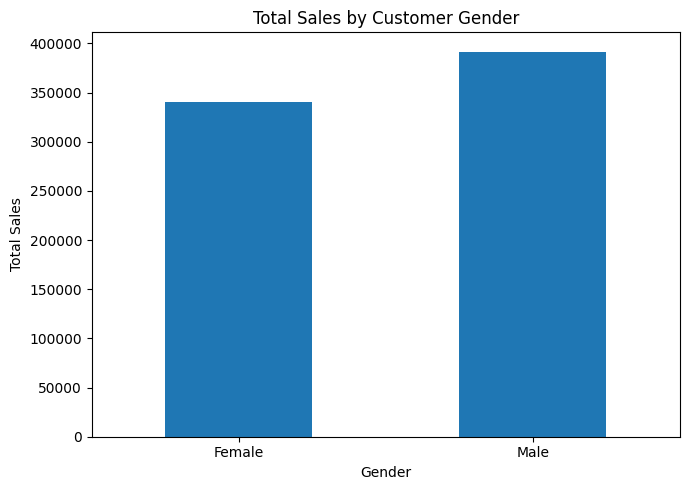

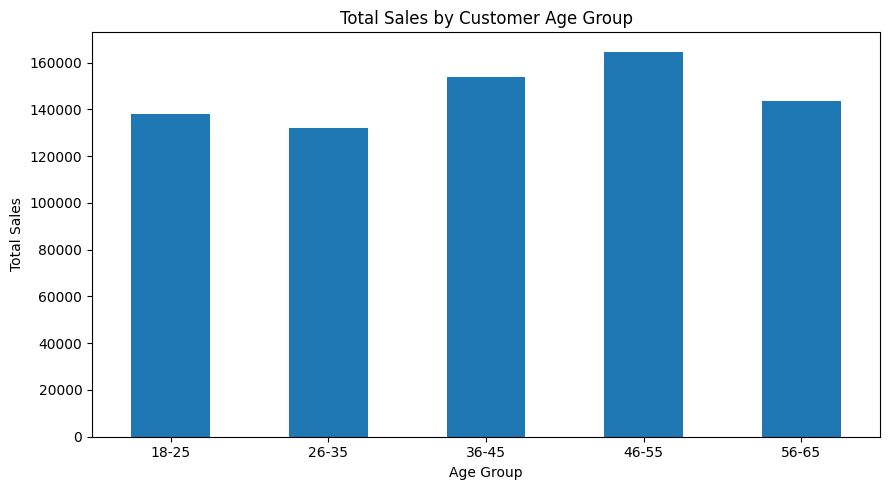

Sales by Gender:


,total_sales
customer_gender,
Female,340157
Male,391633


Sales by Age Group:


,total_sales
age_group,
18-25,137800
26-35,131813
36-45,153837
46-55,164691
56-65,143649


In [6]:

# Sales by gender
gender_sales = df.groupby("customer_gender")["total_sales"].sum()

# Sales by age group
age_sales = df.groupby("age_group", observed=False)["total_sales"].sum()

# Gender sales chart
plt.figure(figsize=(7, 5))
gender_sales.plot(kind="bar")
plt.title("Total Sales by Customer Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Age group sales chart
plt.figure(figsize=(9, 5))
age_sales.plot(kind="bar")
plt.title("Total Sales by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Sales by Gender:")
display(gender_sales)

print("Sales by Age Group:")
display(age_sales)


### Observations

1. Male customers generated higher total sales (391,633) compared to female customers (340,157).
2. The 46–55 age group contributed the highest sales (164,691).
3. The 26–35 age group recorded the lowest sales (131,813).
4. Sales contributions are relatively distributed across all age groups, with no single group dominating the total revenue.
5. The results suggest that customers aged 36–55 are an important segment for retail sales.

## 6. Product Performance Analysis

This section identifies the top 10 products based on total sales revenue to understand which products contribute most to overall business performance.

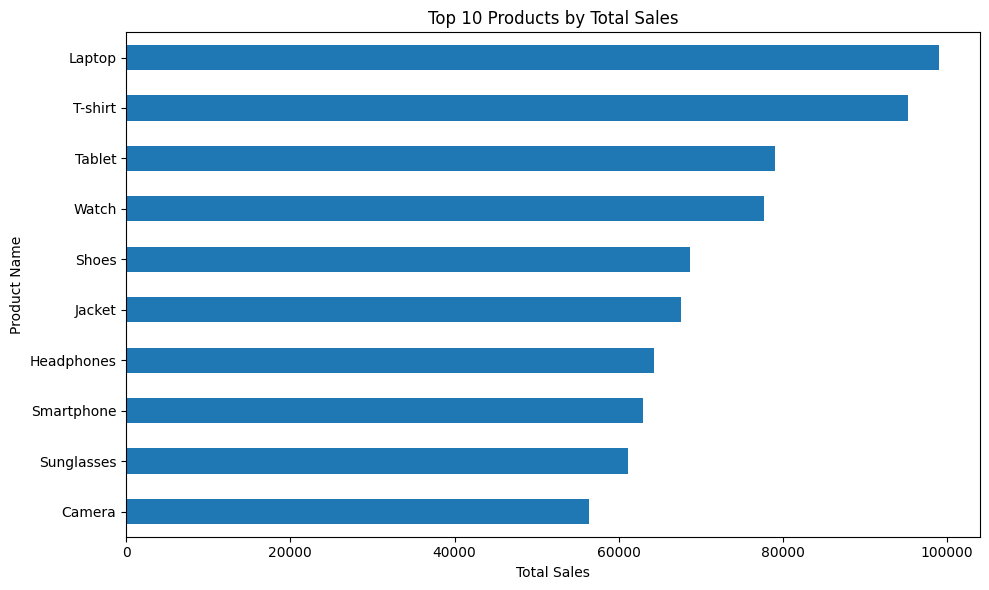

Top 10 Products by Total Sales:


,total_sales
product_name,
Laptop,99040
T-shirt,95243
Tablet,78999
Watch,77642
Shoes,68625
Jacket,67553
Headphones,64234
Smartphone,62988
Sunglasses,61134


In [7]:
# Calculate total sales for each product
product_sales = (
    df.groupby("product_name")["total_sales"]
    .sum()
    .sort_values(ascending=False)
)

# Select the top 10 products
top_10_products = product_sales.head(10)

# Visualise the top 10 products
plt.figure(figsize=(10, 6))
top_10_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

print("Top 10 Products by Total Sales:")
display(top_10_products)

### Observations

1. Laptop generated the highest sales revenue (99,040), making it the best-performing product.
2. T-shirts ranked second with sales of 95,243.
3. Tablets and watches also contributed significantly, generating 78,999 and 77,642 respectively.
4. Cameras recorded the lowest sales among the top 10 products (56,332).
5. The difference between the highest and lowest product sales indicates variation in product performance.

## 7. Revenue Analysis by Product Category

This section compares total sales revenue across product categories to identify which category contributes the most to overall revenue.

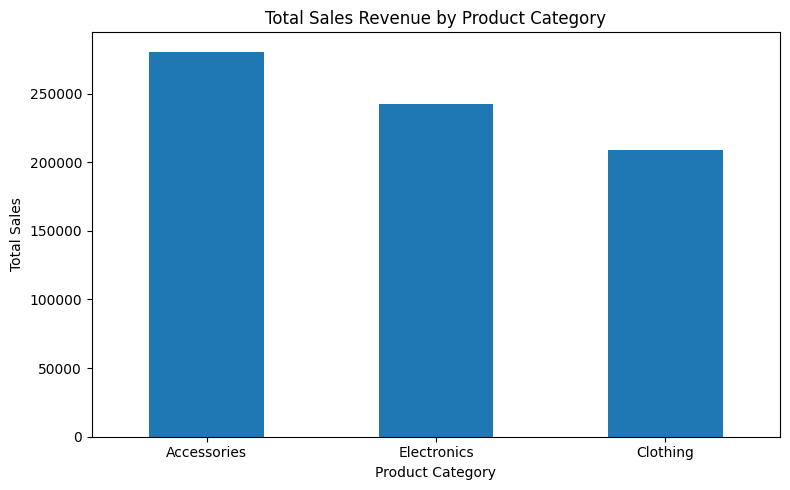

Revenue by Product Category:


,total_sales
category,
Accessories,280575
Electronics,242079
Clothing,209136


In [8]:
# Calculate total sales by category
category_sales = (
    df.groupby("category")["total_sales"]
    .sum()
    .sort_values(ascending=False)
)

# Visualise category revenue
plt.figure(figsize=(8, 5))
category_sales.plot(kind="bar")

plt.title("Total Sales Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Revenue by Product Category:")
display(category_sales)

### Observations

1. Accessories generated the highest revenue of 280,575, making it the leading product category.
2. Electronics ranked second with total sales of 242,079.
3. Clothing recorded the lowest revenue of 209,136 among the three categories.
4. Accessories contributed the largest share of overall sales, indicating strong customer demand for this category.
5. The revenue difference between categories suggests opportunities to improve the performance of lower-performing categories.

## 8. Correlation Analysis

Correlation analysis is used to identify relationships between numerical variables in the dataset. A heatmap helps visualise the strength and direction of these relationships.

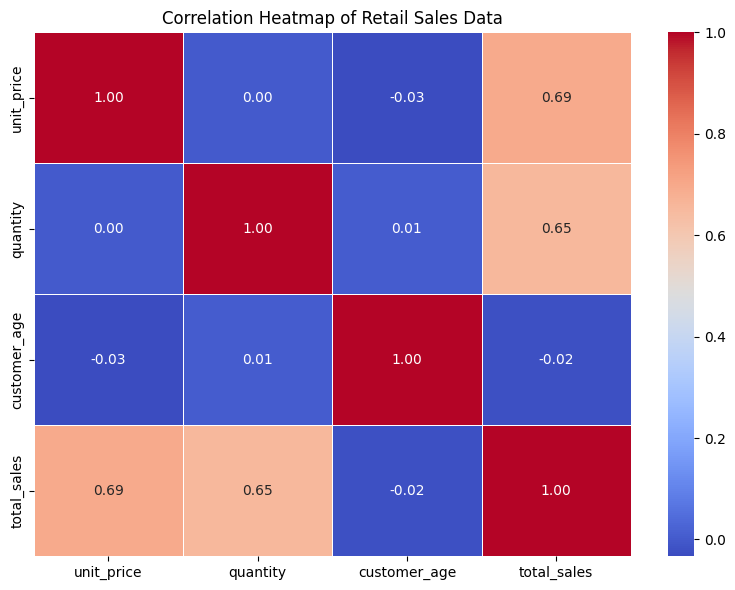

Correlation Matrix:


,unit_price,quantity,customer_age,total_sales
unit_price,1.000000,0.003251,-0.032815,0.694950
quantity,0.003251,1.000000,0.005720,0.653500
customer_age,-0.032815,0.005720,1.000000,-0.022902
total_sales,0.694950,0.653500,-0.022902,1.000000


In [9]:
# Select numerical columns for correlation analysis
numeric_data = df[["unit_price", "quantity", "customer_age", "total_sales"]]

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

# Visualise correlations using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Retail Sales Data")
plt.tight_layout()
plt.show()

print("Correlation Matrix:")
display(correlation_matrix)

### Observations

1. Unit price and total sales have a moderately strong positive correlation (0.69).
2. Quantity and total sales also show a positive correlation (0.65).
3. Customer age has almost no correlation with total sales (-0.02).
4. Unit price and quantity have almost no correlation (0.00).
5. The analysis indicates that product price and quantity purchased are more closely associated with sales revenue than customer age.

## 9. Additional Visualisation – Sales by Country

This section compares sales across different countries to identify the geographical markets contributing to overall revenue.

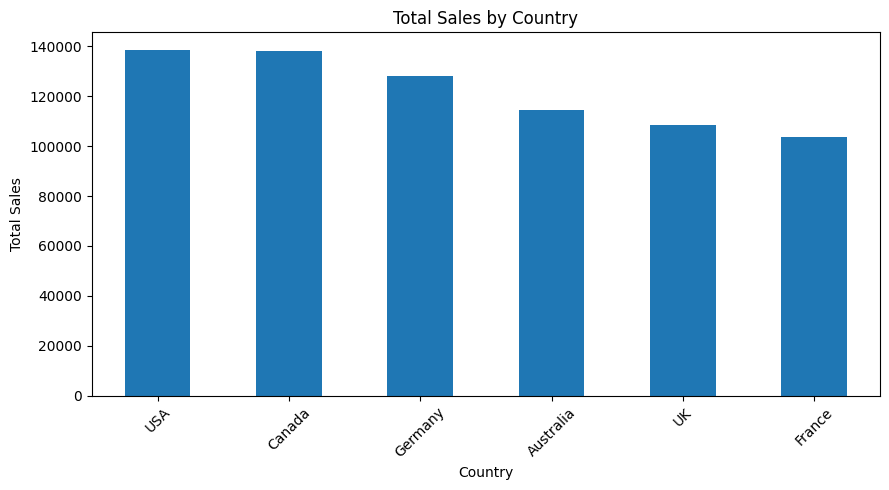

Sales by Country:


,total_sales
country,
USA,138661
Canada,138228
Germany,127995
Australia,114667
UK,108449
France,103790


In [10]:
# Calculate sales by country
country_sales = (
    df.groupby("country")["total_sales"]
    .sum()
    .sort_values(ascending=False)
)

# Create a bar chart
plt.figure(figsize=(9, 5))
country_sales.plot(kind="bar")

plt.title("Total Sales by Country")
plt.xlabel("Country")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Sales by Country:")
display(country_sales)

### Observations

1. The USA recorded the highest total sales of 138,661.
2. Canada ranked second with sales of 138,228, showing performance very close to the USA.
3. Germany generated 127,995 in sales.
4. France recorded the lowest sales of 103,790 among the six countries.
5. Sales were relatively strong across the USA, Canada and Germany, indicating these are important markets for the business.

## 10. Business Recommendations

Based on the exploratory data analysis, the following recommendations can help improve retail business performance:

1. **Focus on top-performing products:** Maintain sufficient stock of laptops and T-shirts, as they generated the highest individual product sales.

2. **Promote the Accessories category:** Since Accessories generated the highest category revenue (280,575), the business should continue investing in this category.

3. **Target important customer segments:** Develop targeted marketing campaigns for customers aged 36–55, particularly the 46–55 age group, which contributed the highest sales.

4. **Improve seasonal sales:** Sales were highest in August but declined considerably during the fourth quarter. Seasonal promotions and targeted campaigns could help improve sales during weaker periods.

5. **Use pricing and quantity strategies:** Since unit price and quantity both have positive correlations with total sales, the business should evaluate suitable pricing, product bundles and volume-based offers.

## 11. Conclusion

This exploratory data analysis provided insights into retail sales performance, customer demographics, product popularity and revenue trends.

The analysis identified Accessories as the highest-revenue category and Laptops as the top-performing individual product. Customers aged 46–55 contributed the highest sales among the age groups. Monthly and quarterly analysis also revealed variations in sales throughout the year.

Correlation analysis showed that unit price and quantity purchased were positively associated with total sales, while customer age had very little relationship with sales revenue.

Overall, this project demonstrates how Python libraries such as Pandas, Matplotlib and Seaborn can be used to analyse retail data, identify patterns and generate actionable business recommendations.